In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import pickle

import sys
sys.path.append('../../../')

# Import methods
from QGP.Soliton_Gen import *
from Utilities import *

import config
i = 1j

path = "../../../Heaven_scripts/Results/Blow_up/Space/blow_up_A_0.65_sigma_0.1_Ns/"
path_save = "Img/Heaven/Space/"

In [2]:
A = 0.65
sigma = 1/10

def gaussian(x):
    output = A * np.exp(-x**2/(2 * sigma**2))
    return output

L = np.pi
k = 1
tf = 2.25e-3

In [3]:
Ns = np.array([5_000, 10_000, 20_000, 40_000, 80_000, 160_000])
Nt = 32_000

base = "blow_up"
norm_inf = []
energies = []
for N in Ns:
    folder_name = path + "blow_up_N_{N}/".format(N=N)
    norm_file = gzip.GzipFile(folder_name + "norm_inf.npy.gz", "r")
    norm_ = np.load(norm_file)
    norm_inf += [norm_]

    energy_file = gzip.GzipFile(folder_name + "energy.npy.gz", "r")
    energy = np.load(energy_file)
    energies += [energy]

sols = []
Nelem = 50
N_times = Nt/Nelem

for j in range(30_081):
    if (j)%N_times==0:
        folder_name = path + "blow_up_N_{N}/".format(N=Ns[0])
        sol_file = gzip.GzipFile(folder_name + "w_"+f"{j:010d}"+".npy.gz", "r")
        sol = np.load(sol_file)
        sols += [sol]

t_file = gzip.GzipFile(folder_name + "time.npy.gz", "r")
t = np.load(t_file)

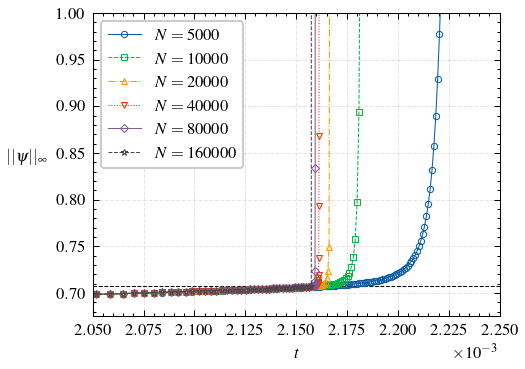

In [9]:
cond = norm_inf[-1]>0
t_cond_ind = t[cond]
indices = my_lin(0, len(t_cond_ind)-1, 50, .028)

plt.hlines(np.sqrt(2)/2, 0, tf, ls="--", color="black", lw=.5)

for j in range(len(Ns)):
    N = Ns[j]
    cond = norm_inf[j]>0
    t_cond = t[cond]
    norm_inf_cond = norm_inf[j][cond]

    post_indices = np.where(t_cond>t_cond_ind[-1])[0]
    if len(post_indices) == 0:
        indices_plot = indices

    else:
        total_post = np.unique(np.linspace(0, len(post_indices)-1, 100, dtype=int))
        indices_plot = np.append(indices, post_indices[total_post])

    plt.plot(t_cond[indices_plot], norm_inf_cond[indices_plot], label=r"$N = {}$".format(N), lw=.5,
             markeredgewidth=.5, ms=3, markerfacecolor="none")

plt.legend()
plt.xlabel(r"$t$")
plt.ylabel(r"$||\psi||_\infty$", rotation='horizontal', ha='right')
plt.ticklabel_format(style='sci',scilimits=(-3,4),axis="x")
plt.ylim(0.675, 1)
plt.xlim(2.05e-3, 2.25e-3)
#plt.grid()

plt.savefig(path_save+"Blow_up_Ns_inf_norm.pdf", dpi=300, bbox_inches = "tight")

plt.show()

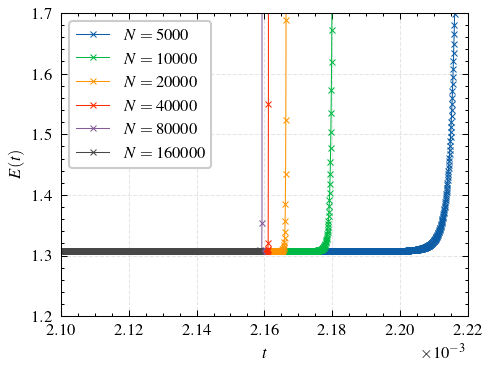

In [6]:
for j in range(len(Ns)):
    N = Ns[j]
    cond = energies[j]>0
    
    plt.plot(t[cond], energies[j][cond], "x-", label=r"$N = {}$".format(N), lw=.5, markeredgewidth=.5, ms=3)

plt.legend()
plt.xlabel(r"$t$")
plt.ylabel(r"$E(t)$")
plt.ticklabel_format(style='sci',scilimits=(-3,4),axis="x")
plt.ylim(1.2, 1.7)
plt.xlim(2.1e-3, 2.22e-3)
plt.show()

In [7]:
ts_blow = []
for j in range(len(Ns)):
    idx_blow_up = np.where(np.abs(energies[j] - energies[j][0])>1)[0][0] #np.argmax(np.gradient(energies[j]))
    ts_blow += [t[idx_blow_up]]

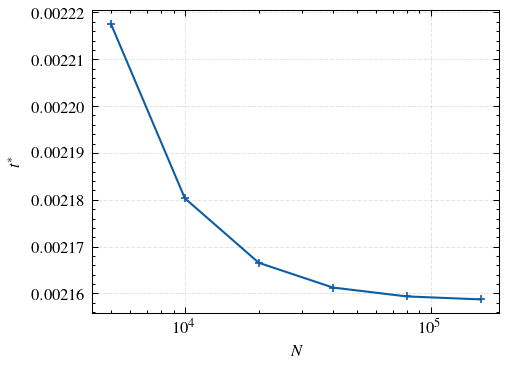

In [8]:
plt.plot(Ns, ts_blow, "+-")
plt.xlabel(r"$N$")
plt.ylabel(r"$t^*$")
plt.xscale("log")
plt.show()